【データ構造】 (178, 14)
【クラス別件数】
 category
0    59
1    71
2    48
Name: count, dtype: int64
【重複行数】 0
【実行環境】scikit-learn 1.6.1


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,category
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


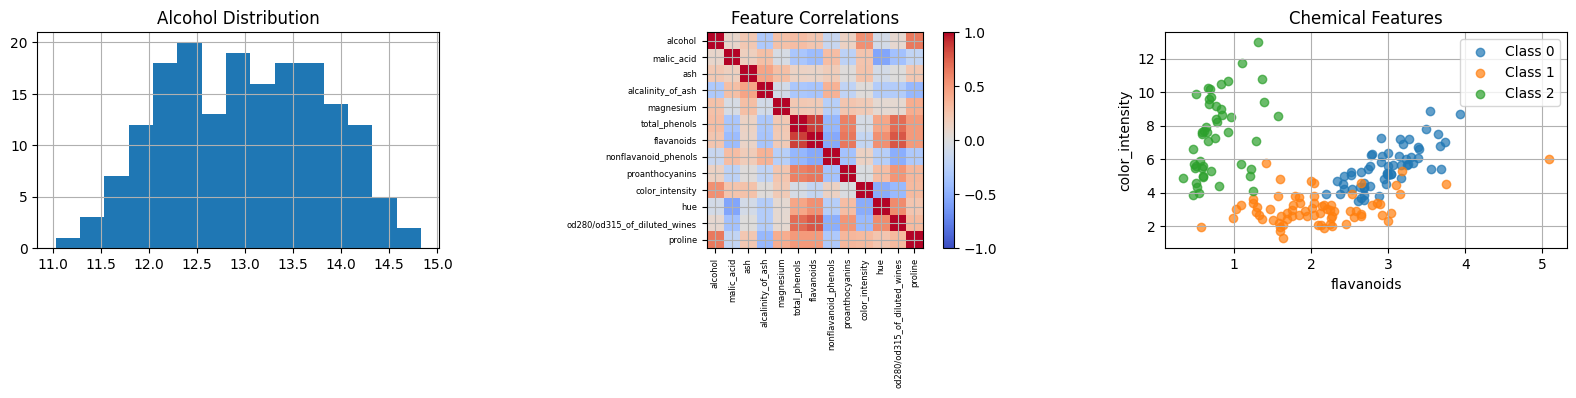


【分類モデル比較】


,Model,Accuracy,Correct
2,Logistic Regression,98.15%,53
1,Random Forest,96.30%,52
0,Decision Tree,92.59%,50
3,Gradient Boosting,92.59%,50



【学習・テスト精度】
Decision Tree: Train=100.00%, Test=92.59%
Random Forest: Train=100.00%, Test=96.30%
Logistic Regression: Train=100.00%, Test=98.15%
Gradient Boosting: Train=100.00%, Test=92.59%

【回帰モデル比較】


,Model,MAE,R2
1,Ridge,0.3832,0.5076
2,Linear SVR,0.3849,0.4954
0,Linear Regression,0.3862,0.5023



【クラスタリング比較】


,Model,ARI
1,Agglomerative,0.8782
0,K-Means,0.8503



【いずれかのモデルが誤分類したデータ】


,Test ID,True,Decision Tree,Random Forest,Logistic Regression,Gradient Boosting
0,9,0,1,0,1,1
1,17,0,1,0,0,1
2,19,0,0,1,0,0
3,39,1,0,1,1,1
4,41,1,2,2,1,2
5,42,2,2,2,2,1



【モデル間の予測不一致件数】
Decision Tree vs Random Forest: 4件
Decision Tree vs Logistic Regression: 3件
Decision Tree vs Gradient Boosting: 2件
Random Forest vs Logistic Regression: 3件
Random Forest vs Gradient Boosting: 4件
Logistic Regression vs Gradient Boosting: 3件

【PCA累積寄与率】54.18%


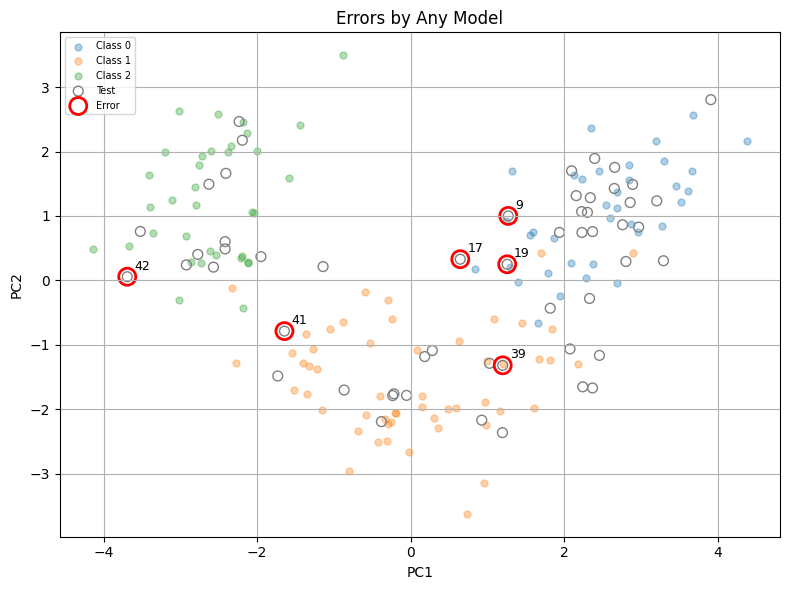

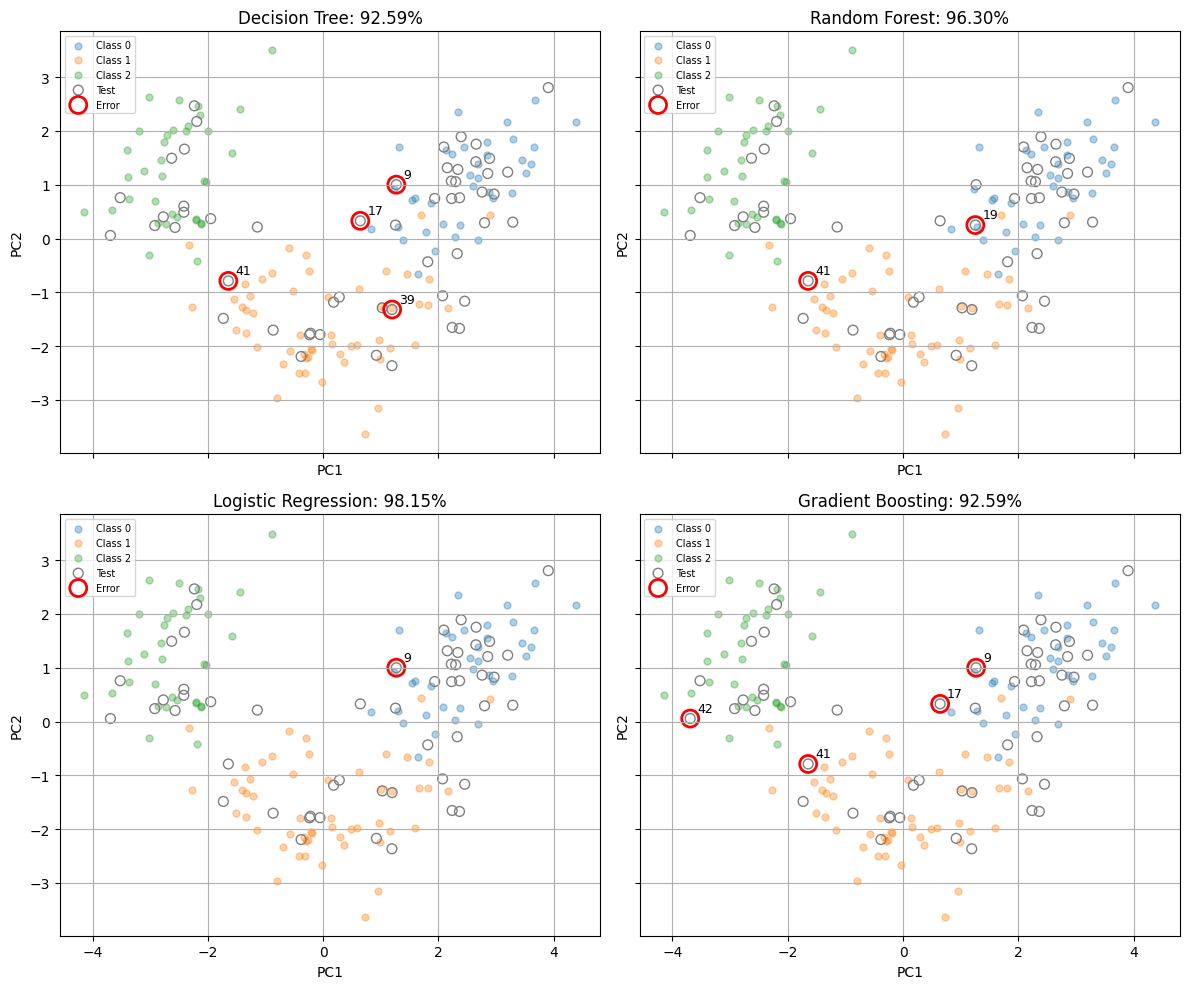

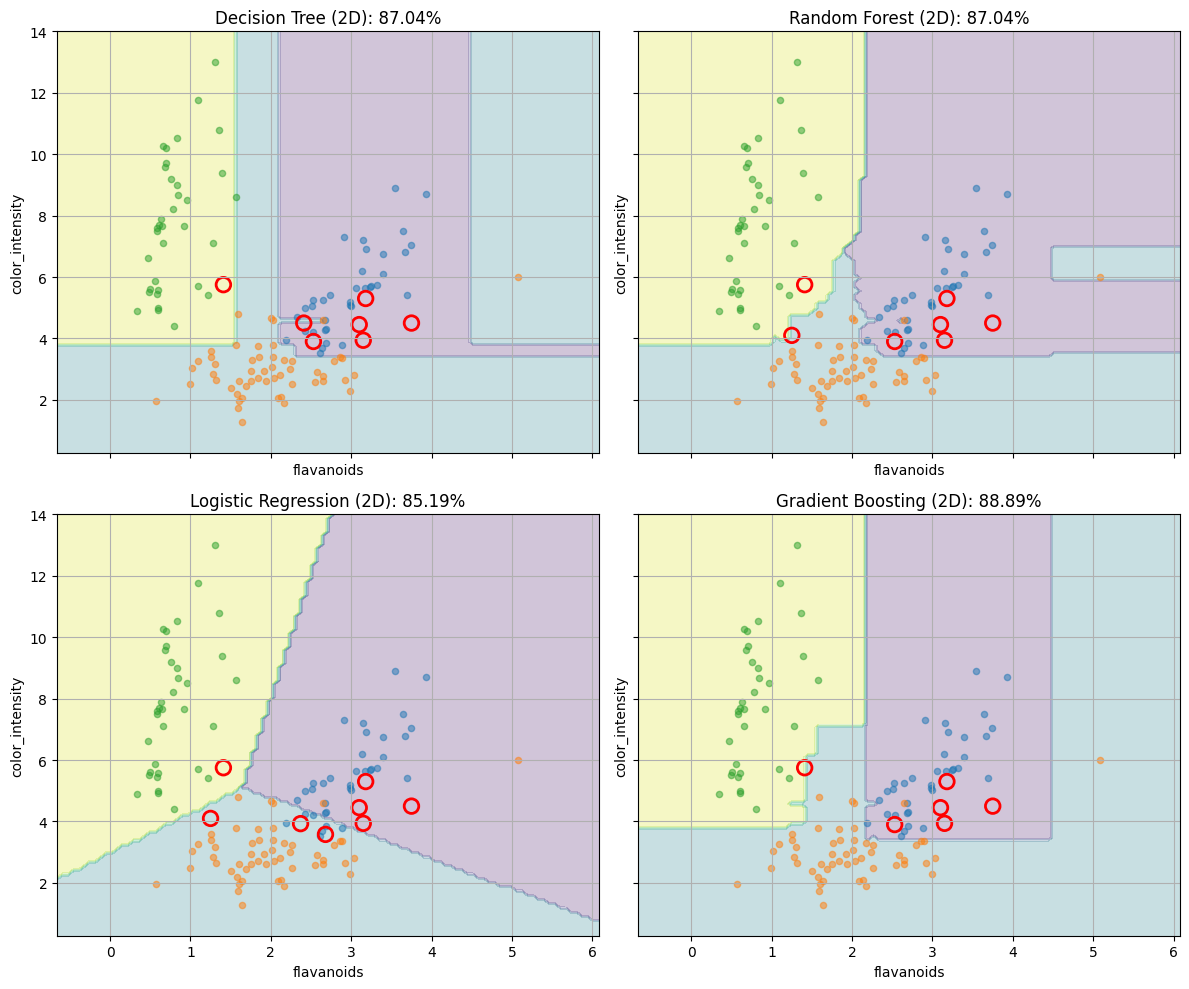


【Permutation Importance】


,Decision Tree,Random Forest,Logistic Regression,Gradient Boosting
alcohol,0.000,0.030,0.046,-0.007
malic_acid,0.000,-0.002,-0.006,0.002
ash,0.000,0.002,0.037,0.000
alcalinity_of_ash,0.000,-0.006,-0.002,0.000
magnesium,0.000,-0.000,0.000,0.006
total_phenols,0.000,-0.007,-0.002,0.000
flavanoids,0.293,0.067,0.046,0.089
nonflavanoid_phenols,0.000,0.000,-0.013,0.000
proanthocyanins,0.000,-0.006,0.009,0.009
color_intensity,0.146,0.059,0.020,0.080


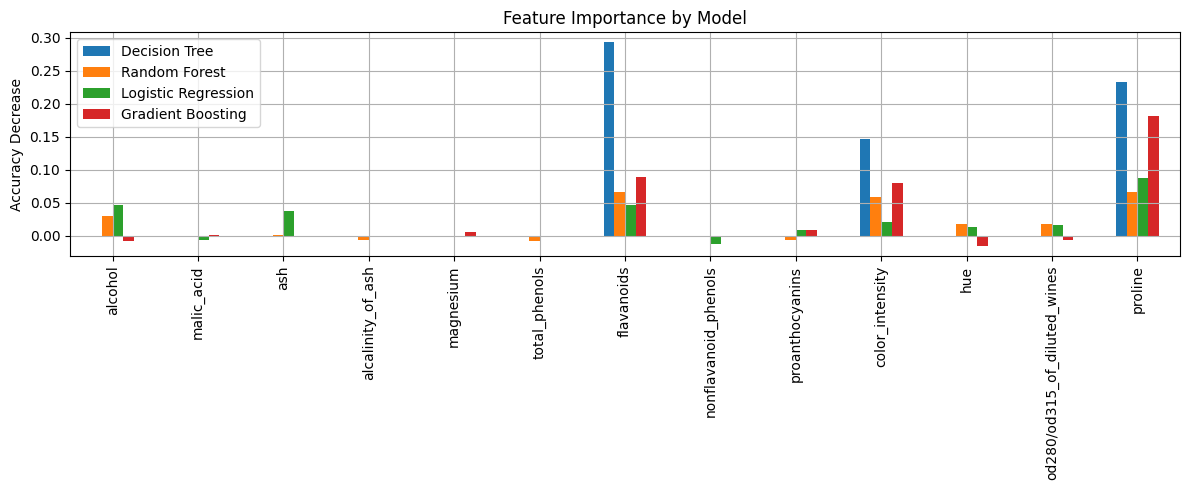


【5分割交差検証】


,Model,Mean,Std
0,Decision Tree,93.53%,3.24%
1,Random Forest,98.33%,3.33%
2,Logistic Regression,96.77%,1.62%
3,Gradient Boosting,92.70%,4.04%


In [13]:
# ============================================================
# 第8章 scikit-learn：データ分析と9モデル比較
#
# 目的：データ理解 → 学習 → 評価 → 可視化 → 考察
# 設計：DRY・責務分離・再現性・データリーク防止
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA
from sklearn.inspection import DecisionBoundaryDisplay, permutation_importance
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.svm import LinearSVR
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import accuracy_score, mean_absolute_error, r2_score, adjusted_rand_score

SEED = 5
plt.rcParams["axes.grid"] = True


# ============================================================
# ① 問題設定・データ構造の確認
# ============================================================

# Wineデータ：178試料 × 13特徴量、正解ラベルは3クラス。
# 分類：成分から種類を予測（教師あり学習）
# 回帰：12成分からalcoholを予測（教師あり学習）
# クラスタリング：正解を使わず類似試料をグループ化（教師なし学習）

data = load_wine()
X, y = data.data, data.target
df = pd.DataFrame(X, columns=data.feature_names)
df["category"] = y

# 入力検証：配列形状と有限値を確認する。
assert X.shape == (178, 13) and len(y) == len(X)
assert np.isfinite(X).all() and not df.isna().any().any()

print("【データ構造】", df.shape)
print("【クラス別件数】\n", df["category"].value_counts().sort_index())
print("【重複行数】", df.duplicated().sum())
print("【実行環境】scikit-learn", sklearn.__version__)
display(df.head(), df.describe().T)


# ============================================================
# ② 探索的データ分析（EDA）
# ============================================================

# ヒストグラム：分布・偏り・外れ値候補を確認。
# 相関行列：特徴量間の線形的な関係を確認。
# 散布図：実際の成分値でクラスが分離するか確認。
# 注意：相関は因果関係ではなく、外れ値も直ちに削除しない。

features = ["flavanoids", "color_intensity"]
ix = [data.feature_names.index(f) for f in features]

fig, ax = plt.subplots(1, 3, figsize=(16, 4))

df["alcohol"].hist(bins=15, ax=ax[0])
ax[0].set_title("Alcohol Distribution")

corr = df.drop(columns="category").corr()
im = ax[1].imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax[1].set_title("Feature Correlations")
ax[1].set_xticks(range(13), data.feature_names, rotation=90, fontsize=6)
ax[1].set_yticks(range(13), data.feature_names, fontsize=6)
fig.colorbar(im, ax=ax[1])

for c in np.unique(y):
    ax[2].scatter(X[y == c, ix[0]], X[y == c, ix[1]],
                  label=f"Class {c}", alpha=.7)
ax[2].set(xlabel=features[0], ylabel=features[1],
          title="Chemical Features")
ax[2].legend()
plt.tight_layout()
plt.show()


# ============================================================
# ③ 学習・テストデータの分割
# ============================================================

# 学習70%、テスト30%。全モデルで同じ分割を使用。
# random_stateで再現性を確保する。
# 前処理のfitは学習データだけで実行し、情報漏洩を防ぐ。

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=.3, random_state=SEED
)


# ============================================================
# ④ 分類：4モデルの学習と正解率比較
# ============================================================

# 決定木：しきい値による条件分岐
# RF：複数の決定木による集約
# LR：特徴量の線形結合からクラス確率を推定
# GB：誤差を改善する方向に決定木を逐次追加
# Pipeline：標準化と学習を一体化し、再利用・漏洩防止。

classification_models = {
    "Decision Tree": DecisionTreeClassifier(random_state=3),
    "Random Forest": RandomForestClassifier(random_state=3),
    "Logistic Regression": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=1000)),
    "Gradient Boosting": GradientBoostingClassifier(random_state=3)
}

# 辞書とループを使い、モデルごとの重複コードを削減（DRY）。
predictions, results = {}, []

for name, model in classification_models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    predictions[name] = pred
    results.append([name, accuracy_score(y_test, pred),
                    np.sum(pred == y_test)])

classification_df = pd.DataFrame(
    results, columns=["Model", "Accuracy", "Correct"]
).sort_values("Accuracy", ascending=False)

print("\n【分類モデル比較】")
display(classification_df.style.format({"Accuracy": "{:.2%}"}))

# 評価：正解率だけでなく、学習・テスト性能差も確認する。
# 過学習：学習データには高精度だが未知データで精度が低い状態。
print("\n【学習・テスト精度】")
for name, model in classification_models.items():
    print(f"{name}: Train={model.score(X_train, y_train):.2%}, "
          f"Test={model.score(X_test, y_test):.2%}")


# ============================================================
# ⑤ 回帰：3モデルの比較
# ============================================================

# 目的変数をアルコール濃度に変更。
# 入力Xからalcohol列を除外し、正解の混入を防ぐ。
# MAEは小さいほど良く、R²は1に近いほど良い。

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X[:, 1:], X[:, 0], test_size=.3, random_state=SEED
)

regression_models = {
    "Linear Regression": LinearRegression(),
    "Ridge": make_pipeline(StandardScaler(), Ridge()),
    "Linear SVR": make_pipeline(
        StandardScaler(), LinearSVR(random_state=3, max_iter=20000))
}

results = []
for name, model in regression_models.items():
    model.fit(Xr_train, yr_train)
    pred = model.predict(Xr_test)
    results.append([name, mean_absolute_error(yr_test, pred),
                    r2_score(yr_test, pred)])

regression_df = pd.DataFrame(
    results, columns=["Model", "MAE", "R2"]
).sort_values("MAE")

print("\n【回帰モデル比較】")
display(regression_df.round(4))


# ============================================================
# ⑥ クラスタリング：2モデルの比較
# ============================================================

# 学習時に正解ラベルを使わず、成分の類似性から3群を形成。
# ARI：真のラベルとの一致度。1が完全一致、0付近が偶然程度。
# クラスタ番号と正解ラベルの数字は一致しなくてもよい。
# 今回はテスト54件を直接クラスタ化する探索的比較。
# 分類モデルの「未知データ予測」とは評価条件が異なる。

scaler = StandardScaler().fit(X_train)
X_test_scaled = scaler.transform(X_test)

clustering_models = {
    "K-Means": KMeans(n_clusters=3, random_state=3, n_init=10),
    "Agglomerative": AgglomerativeClustering(n_clusters=3)
}

results = []
for name, model in clustering_models.items():
    labels = model.fit_predict(X_test_scaled)
    results.append([name, adjusted_rand_score(y_test, labels)])

cluster_df = pd.DataFrame(
    results, columns=["Model", "ARI"]
).sort_values("ARI", ascending=False)

print("\n【クラスタリング比較】")
display(cluster_df.round(4))


# ============================================================
# ⑦ 誤分類の分析
# ============================================================

# 各モデルの誤分類位置を保存する。
# 行番号は元データではなく、テストデータ内の位置。
# 正解率が等しくても、誤分類した試料が同じとは限らない。

errors = {
    name: pred != y_test
    for name, pred in predictions.items()
}
any_error = np.logical_or.reduce(list(errors.values()))
error_ids = np.where(any_error)[0]

error_df = pd.DataFrame({
    "Test ID": error_ids, "True": y_test[error_ids]
})
for name, pred in predictions.items():
    error_df[name] = pred[error_ids]

print("\n【いずれかのモデルが誤分類したデータ】")
display(error_df)

print("\n【モデル間の予測不一致件数】")
names = list(predictions)
for i, a in enumerate(names):
    for b in names[i + 1:]:
        print(f"{a} vs {b}: {np.sum(predictions[a] != predictions[b])}件")


# ============================================================
# ⑧ PCA：13特徴量のデータ構造と誤分類を可視化
# ============================================================

# PCAは分散の大きい方向を抽出する教師なし次元削減。
# 正解クラスを最もよく分離する方向とは限らない。
# PCAは学習用データだけでfitし、テストにはtransform。
# 13次元の予測結果を2次元に投影して表示する。

pca = PCA(n_components=2).fit(scaler.transform(X_train))
Z_train = pca.transform(scaler.transform(X_train))
Z_test = pca.transform(X_test_scaled)

print(f"\n【PCA累積寄与率】{pca.explained_variance_ratio_.sum():.2%}")

# 共通描画関数：可視化ロジックを再利用（責務分離）。
def plot_pca(ax, mask, title):
    for c in np.unique(y_train):
        ax.scatter(*Z_train[y_train == c].T, alpha=.35,
                   s=25, label=f"Class {c}")
    ax.scatter(*Z_test.T, facecolors="none", edgecolors="gray",
               s=50, label="Test")
    ax.scatter(*Z_test[mask].T, facecolors="none", edgecolors="red",
               s=150, linewidths=2, label="Error")
    for idx in np.where(mask)[0]:
        ax.annotate(str(idx), Z_test[idx], xytext=(5, 5),
                    textcoords="offset points", fontsize=9)
    ax.set(xlabel="PC1", ylabel="PC2", title=title)
    ax.legend(fontsize=7)

# 図1：4モデルのいずれかが間違えたデータ（前回は6件）。
fig, ax = plt.subplots(figsize=(8, 6))
plot_pca(ax, any_error, "Errors by Any Model")
plt.tight_layout()
plt.show()

# 図2：4モデルの誤分類位置を同一尺度で比較。
fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharex=True, sharey=True)
for ax, (name, mask) in zip(axes.flat, errors.items()):
    plot_pca(ax, mask, f"{name}: {np.mean(~mask):.2%}")
plt.tight_layout()
plt.show()

# 注意：PCA上で近い点が元の13次元でも近いとは限らない。
# 赤丸が集まる位置は、分類が難しい領域の候補にすぎない。


# ============================================================
# ⑨ 決定境界：モデルの規則性の違いを可視化
# ============================================================

# 13次元の決定境界は直接散布図にできない。
# そのため、2特徴量だけで別のモデルを学習する。
# 元の13特徴量モデルの評価精度とは区別する。
# 同じ学習/テスト分割を使い、モデル間の条件を統一。

fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharex=True, sharey=True)

for ax, (name, base) in zip(axes.flat, classification_models.items()):

    # 可視化専用の2特徴量モデルを新規作成する。
    from sklearn.base import clone
    model = clone(base)
    model.fit(X_train[:, ix], y_train)
    pred = model.predict(X_test[:, ix])

    DecisionBoundaryDisplay.from_estimator(
        model, X[:, ix], ax=ax, alpha=.25
    )

    for c in np.unique(y_train):
        ax.scatter(*X_train[y_train == c][:, ix].T,
                   s=20, alpha=.5, label=f"Class {c}")

    # 2特徴量モデルで間違えたテストデータを赤丸表示。
    mask = pred != y_test
    ax.scatter(*X_test[mask][:, ix].T, facecolors="none",
               edgecolors="red", s=110, linewidths=2)

    ax.set(xlabel=features[0], ylabel=features[1],
           title=f"{name} (2D): {accuracy_score(y_test, pred):.2%}")

plt.tight_layout()
plt.show()

# 【境界の解釈】
# 決定木：縦横の条件分岐による階段状の境界。
# RF・GB：複数の木を組み合わせた複雑な境界。
# LR：線形なクラス境界。
# 複雑な境界が必ず高精度になるわけではない。


# ============================================================
# ⑩ 特徴量重要度の比較
# ============================================================

# Permutation Importance：
# 特徴量をシャッフルしたときの正解率低下を測定。
# 4モデルに共通の基準で特徴量への依存度を比較する。
# 相関する特徴量がある場合、重要度の解釈には注意。
# 重要度は因果関係を示さない。

importance = {}
for name, model in classification_models.items():
    result = permutation_importance(
        model, X_test, y_test,
        n_repeats=10, random_state=SEED, scoring="accuracy"
    )
    importance[name] = result.importances_mean

importance_df = pd.DataFrame(importance, index=data.feature_names)

print("\n【Permutation Importance】")
display(importance_df.round(3))

importance_df.plot.bar(figsize=(12, 5))
plt.title("Feature Importance by Model")
plt.ylabel("Accuracy Decrease")
plt.tight_layout()
plt.show()


# ============================================================
# ⑪ 交差検証：評価結果の安定性確認
# ============================================================

# 単一の70:30分割では偶然の影響が残る。
# 学習用124件を5分割して性能の平均とばらつきを確認。
# 最終テスト54件は交差検証に使用しない。
# ただし今回は既にテスト結果を見ているため、
# 厳密に独立した最終評価には新しいデータが必要。

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

results = []
for name, model in classification_models.items():
    scores = cross_val_score(model, X_train, y_train,
                             cv=cv, scoring="accuracy")
    results.append([name, scores.mean(), scores.std()])

cv_df = pd.DataFrame(results, columns=["Model", "Mean", "Std"])
print("\n【5分割交差検証】")
display(cv_df.style.format({"Mean": "{:.2%}", "Std": "{:.2%}"}))


# ============================================================
# ⑫ 結論とソフトウェア工学
# ============================================================

# データサイエンス：
# ・データ構造と品質を理解してからモデルを選ぶ。
# ・分類、回帰、クラスタリングで評価指標を使い分ける。
# ・誤分類位置、決定境界、交差検証から原因を検討する。
#
# ソフトウェア工学：
# ・DRY：辞書・ループ・関数で重複を削減。
# ・責務分離：データ準備、学習、評価、表示を区分。
# ・再現性：乱数シードとライブラリバージョンを管理。
# ・品質保証：入力検証、データリーク防止、テスト。
# ・保守性：モデル追加・変更時の修正箇所を最小化。
#
# 次の発展：関数の単体テスト、設定管理、CI、
# モデル保存、依存関係の固定、独立データでの再評価。
# ============================================================
